
# Finance Analytics & Transaction Risk Monitoring
### Python Statistical Analysis & Business Decision Support

**Project Scope:** 50,000 financial transactions | 5,000 customers | January 2023 – April 2026

**Tech Stack:** Python (Pandas, NumPy, SciPy, Matplotlib, Statsmodels), Microsoft SQL Server, Power BI

## Business Context

A financial services organization needs to monitor transaction reliability, understand customer engagement, and manage risk investigation workloads efficiently.

This project analyzes validated transaction and customer data to identify operational patterns and develop evidence-based recommendations.

## Analytical Objectives

1. **Transaction Reliability:** Evaluate payment channel performance and identify potential failure concentrations.
2. **Operational Monitoring:** Investigate unusual changes in monthly transaction failure rates.
3. **Customer Engagement:** Develop behavioral cohorts using transaction frequency.
4. **Risk Operations:** Evaluate investigation workload and existing fraud-flag coverage under alternative risk-score thresholds.

## Data & Methodology

Data is extracted from validated SQL Server views in `FinanceAnalyticsDB`. Python is used for statistical analysis, behavioral segmentation, and decision-support visualizations, while Power BI provides interactive business reporting.

## Important Considerations

- Transaction value is not equivalent to company revenue.
- Existing fraud flags are not independently verified fraud outcomes.
- Statistical screening results are exploratory and do not establish causation.
- Recommendations describe potential business actions, not implemented improvements.



## 1. Environment Setup

Initialize the libraries required for data analysis, statistical testing, visualization, and SQL Server connectivity.

**Data Architecture:** SQL Server handles data cleaning and validation; Python performs statistical and behavioral analysis on validated database views.


In [1]:

# Data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Statistical analysis
from scipy import stats
from statsmodels.stats.multitest import multipletests

# SQL Server connectivity
import pyodbc
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Notebook display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

plt.rcParams["figure.figsize"] = (10, 5)



## 2. Data Acquisition — SQL Server

**Source:** `FinanceAnalyticsDB`, Microsoft SQL Server

**Validated Views:**
- `validated.clean_transactions`
- `validated.clean_customers`

Python connects through SQLAlchemy and PyODBC using Windows Authentication. The analysis reads validated data without modifying the underlying SQL Server tables.

**Reproducibility:** The SQL Server instance, database, and validated views must be available before executing the notebook.


In [2]:
# Local development configuration
# Update these values for a different SQL Server environment
server = "localhost"
database = "FinanceAnalyticsDB"

# Identify installed Microsoft SQL Server ODBC driver
available_drivers = pyodbc.drivers()

preferred_drivers = [
    "ODBC Driver 18 for SQL Server",
    "ODBC Driver 17 for SQL Server"
]

driver = next(
    (d for d in preferred_drivers if d in available_drivers),
    None
)

if driver is None:
    raise RuntimeError(
        "Microsoft SQL Server ODBC Driver 17 or 18 "
        "is not installed."
    )

# Windows Authentication connection string
connection_string = (
    f"DRIVER={{{driver}}};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
    "Encrypt=yes;"
    "TrustServerCertificate=yes;"
)

# Create SQLAlchemy connection engine
connection_url = URL.create(
    "mssql+pyodbc",
    query={"odbc_connect": connection_string}
)

engine = create_engine(
    connection_url,
    pool_pre_ping=True
)

# Test database connection
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT DB_NAME() AS database_name")
    )

    connected_database = result.scalar()

    print("Connection Status: Successful")
    print("Connected Database:", connected_database)
    print("ODBC Driver:", driver)

C:\Users\Raghu Poojary\AppData\Local\Temp\ipykernel_19932\3821242425.py:49: SAWarning: Unrecognized server version info '17.0.1000.7'.  Some SQL Server features may not function properly.
  with engine.connect() as connection:


Connection Status: Successful
Connected Database: FinanceAnalyticsDB
ODBC Driver: ODBC Driver 18 for SQL Server



### 2.1 Transaction Data Extraction

Load validated transaction records from `validated.clean_transactions` into Pandas.

The SQL validation layer handles deduplication and standardization; Python uses these records for downstream analysis.


In [3]:

# Load validated transaction records
query_transactions = """
SELECT *
FROM validated.clean_transactions
"""

with engine.connect() as connection:
    df_transactions = pd.read_sql(
        text(query_transactions),
        connection
    )

print(f"Transactions loaded: {len(df_transactions):,}")
print(f"Columns: {df_transactions.shape[1]}")

display(df_transactions.head())


Transactions loaded: 50,000
Columns: 17


,transaction_id,transaction_date,account_id,customer_id,transaction_type,channel,merchant_category,amount,fee_amount,tax_amount,currency,transaction_status,is_fraud,risk_score,reference_no,amount_quality_flag,fee_quality_flag
0,T00000001,2025-02-21,A001795,C00629,Investment,Mobile App,Food Delivery,"24,721.24",123.61,22.25,INR,Success,No,63,REF8835851139\r,Normal,Available
1,T00000002,2023-01-28,A004859,C02038,Transfer,UPI,Groceries,"18,711.77",93.56,16.84,INR,Success,No,21,REF9409811139\r,Normal,Available
2,T00000003,2024-06-25,A003081,C00652,Transfer,Net Banking,Groceries,"45,865.90",0.00,0.00,INR,Success,No,25,REF1704628312\r,Normal,Available
3,T00000004,2025-02-20,A004122,C01357,Withdrawal,Auto Debit,Salary,"4,310.91",NaN,0.78,INR,Failed,No,43,REF3937614748\r,Normal,Missing Fee
4,T00000005,2024-08-06,A004150,C02547,Deposit,Branch,Shopping,"11,646.45",0.00,0.00,INR,Success,No,5,REF5855288886\r,Normal,Available



### 2.2 Customer Data Extraction

Load customer attributes from `validated.clean_customers` to support customer-level behavioral analysis and segmentation.


In [4]:

# Load validated customer records
query_customers = """
SELECT *
FROM validated.clean_customers
"""

with engine.connect() as connection:
    df_customers = pd.read_sql(
        text(query_customers),
        connection
    )

print(f"Customers loaded: {len(df_customers):,}")
print(f"Columns: {df_customers.shape[1]}")

display(df_customers.head())


Customers loaded: 5,000
Columns: 11


,customer_id,first_name,second_name,gender,date_of_birth,city,state,occupation,customer_segment,annual_income,join_date
0,C00001,Karan,Chopra,Male,1982-10-09,Kolkata,West Bengal,Retired,SME,"988,416.79",2021-04-15
1,C00002,Ishaan,Patel,Male,1983-10-07,Chandigarh,Chandigarh,Salaried,Premium,"457,149.28",2022-04-06
2,C00003,Krishna,Patel,Male,1989-11-27,Hyderabad,Telangana,Retired,Retail,"378,907.24",2026-03-06
3,C00004,Amit,Verma,Male,1970-08-13,Lucknow,Uttar Pradesh,Salaried,Retail,"299,085.16",2021-07-16
4,C00005,Reyansh,Jain,Female,1977-02-07,Ahmedabad,Gujarat,Freelancer,SME,"775,436.07",2023-02-23



### 2.3 Analytical Data Integrity

**Objective:** Verify identifier uniqueness, customer referential integrity, and completeness of essential analytical fields before conducting statistical analysis.

The checks below are Python-side safeguards on data already validated in SQL Server.


In [5]:

# Analytical integrity checks

required_transaction_fields = [
    "transaction_id", "customer_id", "transaction_date",
    "channel", "transaction_type", "transaction_status",
    "risk_score"
]

checks = {
    "Duplicate transaction IDs":
        df_transactions["transaction_id"].duplicated().sum(),

    "Duplicate customer IDs":
        df_customers["customer_id"].duplicated().sum(),

    "Unmatched customer IDs":
        (~df_transactions["customer_id"].isin(
            df_customers["customer_id"]
        )).sum(),

    "Missing essential transaction values":
        df_transactions[
            required_transaction_fields
        ].isna().sum().sum()
}

validation_summary = pd.DataFrame(
    {
        "Validation Check": list(checks.keys()),
        "Issues Found": list(checks.values())
    }
)

validation_summary["Status"] = np.where(
    validation_summary["Issues Found"] == 0,
    "PASS",
    "REVIEW"
)

display(
    validation_summary.style
    .map(
        lambda value: (
            "color: #16856b; font-weight: bold"
            if value == "PASS"
            else "color: #c2410c; font-weight: bold"
        ),
        subset=["Status"]
    )
)

if (validation_summary["Issues Found"] > 0).any():
    raise ValueError(
        "Data integrity checks failed. Review the source data."
    )

print("Data integrity checks passed.")


,Validation Check,Issues Found,Status
0,Duplicate transaction IDs,0,PASS
1,Duplicate customer IDs,0,PASS
2,Unmatched customer IDs,0,PASS
3,Missing essential transaction values,0,PASS


Data integrity checks passed.



## 3. Payment Channel Performance Analysis

**Business Question:** Do transaction success rates differ meaningfully across payment channels?

**Approach:** Compare channel-level success rates and use a chi-square test to evaluate the association between payment channel and transaction outcome.

**Metric:** Success Rate = Successful Transactions / Total Transaction Attempts × 100

Pending transactions remain in the denominator.

**Decision Context:** Determine whether observed channel differences justify further operational investigation.


In [6]:
# Channel-level transaction performance analysis

# Create a working copy without modifying the original DataFrame
df_channel = df_transactions.copy()

# Standardize transaction status for analysis
df_channel["status_clean"] = (
    df_channel["transaction_status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Calculate transaction counts by channel and status
channel_summary = (
    pd.crosstab(
        df_channel["channel"],
        df_channel["status_clean"]
    )
    .reindex(
        columns=["success", "failed", "pending"],
        fill_value=0
    )
)

# Calculate total attempts
channel_summary["total_transactions"] = (
    channel_summary[["success", "failed", "pending"]].sum(axis=1)
)

# Calculate success rate
channel_summary["success_rate_pct"] = (
    channel_summary["success"]
    / channel_summary["total_transactions"]
    * 100
)

# Rename columns for readability
channel_summary = channel_summary.rename(
    columns={
        "success": "successful_transactions",
        "failed": "failed_transactions",
        "pending": "pending_transactions"
    }
)

# Rank by success rate
channel_summary = channel_summary.sort_values(
    "success_rate_pct",
    ascending=False
)

display(channel_summary.round(2))

status_clean,successful_transactions,failed_transactions,pending_transactions,total_transactions,success_rate_pct
channel,,,,,
Net Banking,6159,682,272,7113,86.59
POS,6129,727,254,7110,86.20
Branch,6207,731,290,7228,85.87
UPI,6168,710,321,7199,85.68
Mobile App,6085,703,315,7103,85.67
Auto Debit,6016,764,291,7071,85.08
ATM,6105,779,292,7176,85.08


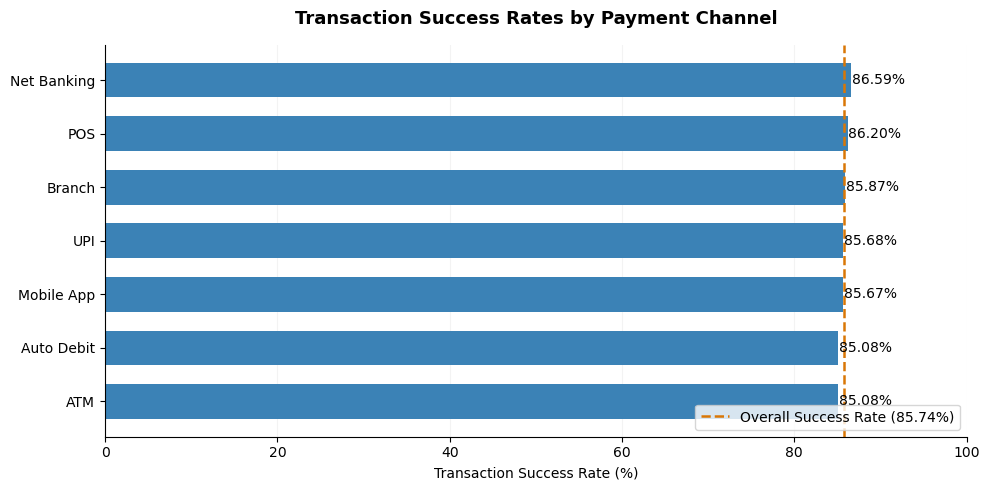

In [7]:

# Visualize observed channel success rates

plot_data = (
    channel_summary
    .sort_values("success_rate_pct")
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_data.index,
    plot_data["success_rate_pct"],
    color="#3B82B6",
    height=0.65
)

# Overall success-rate benchmark
overall_success_rate = (
    df_channel["status_clean"].eq("success").mean() * 100
)

ax.axvline(
    overall_success_rate,
    color="#D97706",
    linestyle="--",
    linewidth=1.8,
    label=f"Overall Success Rate ({overall_success_rate:.2f}%)"
)

# Display percentage labels
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, 100)
ax.set_xlabel("Transaction Success Rate (%)")
ax.set_ylabel("")
ax.set_title(
    "Transaction Success Rates by Payment Channel",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 3.1 Statistical Hypothesis Testing

**H₀:** Payment channel and transaction success are independent.

**H₁:** Payment channel and transaction success are associated.

**Method:** Chi-square test of independence using successful versus not-successful outcomes, with Cramér's V to measure association strength.

**Significance Level:** α = 0.05

**Considerations:** The test assumes independent observations. Repeated transactions from the same customer may violate this assumption, and the test does not control for transaction characteristics.


In [8]:
# Chi-Square Test: Payment Channel vs Transaction Success

# Create a binary transaction outcome
df_channel["transaction_outcome"] = np.where(
    df_channel["status_clean"] == "success",
    "Successful",
    "Not Successful"
)

# Create contingency table
contingency_table = pd.crosstab(
    df_channel["channel"],
    df_channel["transaction_outcome"]
)

print("Contingency Table:")
display(contingency_table)

# Perform Chi-Square Test of Independence
chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(
            contingency_table.shape[0] - 1,
            contingency_table.shape[1] - 1
        )
    )
)

# Check expected frequencies
min_expected = expected.min()

print("\nStatistical Test Results")
print("-" * 40)
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"Degrees of Freedom: {dof}")
print(f"P-Value: {p_value:.6f}")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"Minimum Expected Frequency: {min_expected:.2f}")

# Interpret hypothesis test
alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis")
    print("There is evidence of an association between")
    print("payment channel and transaction success.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")
    print("There is insufficient statistical evidence")
    print("of an association between payment channel")
    print("and transaction success.")

Contingency Table:


transaction_outcome,Not Successful,Successful
channel,,
ATM,1071,6105
Auto Debit,1055,6016
Branch,1021,6207
Mobile App,1018,6085
Net Banking,954,6159
POS,981,6129
UPI,1031,6168



Statistical Test Results
----------------------------------------
Chi-Square Statistic: 10.6981
Degrees of Freedom: 6
P-Value: 0.098166
Cramér's V: 0.0146
Minimum Expected Frequency: 1008.47

Decision: Fail to Reject the Null Hypothesis
There is insufficient statistical evidence
of an association between payment channel
and transaction success.



### 3.2 Findings & Business Implications

**Statistical Results**
- Chi-square statistic: 10.6981
- p-value: 0.0982
- Cramér's V: 0.0146

**Finding:** No statistically significant overall association was detected between payment channel and transaction success at the 5% significance level.

Net Banking recorded the highest observed success rate (86.59%), while ATM and Auto Debit recorded approximately 85.08%.

**Business Implication:** The observed channel differences alone do not justify major channel-specific operational investments.

**Recommendation:** Investigate transaction types, failure reasons, and operational patterns before prioritizing channel-specific interventions.

**Limitation:** Results are observational and do not establish that all channels have identical underlying success probabilities.



## 4. Operational Failure Analysis

**Business Question:** Which payment channel and transaction type combinations contribute the most failed transactions?

**Approach:** Aggregate transaction attempts and failures by channel and transaction type, then compare failure volumes, failure rates, and contributions to total failures.

**Key Metrics**
- **Failure Rate:** Failed transactions / Total attempts × 100
- **Failure Contribution:** Combination failures / All failed transactions × 100

**Business Objective:** Identify high-volume failure categories for operational investigation without assuming that high failure counts indicate poor channel performance.


In [9]:
# Operational failure analysis by channel and transaction type

# Group transactions by channel and transaction type
failure_analysis = (
    df_channel.groupby(
        ["channel", "transaction_type"]
    )
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=(
            "status_clean",
            lambda x: (x == "failed").sum()
        )
    )
    .reset_index()
)

# Calculate failure rate
failure_analysis["failure_rate_pct"] = (
    failure_analysis["failed_transactions"]
    / failure_analysis["total_transactions"]
    * 100
)

# Calculate contribution to overall failures
total_failures = (
    df_channel["status_clean"] == "failed"
).sum()

failure_analysis["failure_contribution_pct"] = (
    failure_analysis["failed_transactions"]
    / total_failures
    * 100
)

# Rank by failure count
failure_analysis = failure_analysis.sort_values(
    by=["failed_transactions", "failure_rate_pct"],
    ascending=False
)

# Display top 10 combinations
print("Top 10 Channel-Transaction Type Combinations by Failure Count")

display(
    failure_analysis.head(10).round(2)
)

Top 10 Channel-Transaction Type Combinations by Failure Count


,channel,transaction_type,total_transactions,failed_transactions,failure_rate_pct,failure_contribution_pct
36,Mobile App,Loan EMI,1313,138,10.51,2.71
18,Auto Debit,Transfer,1269,137,10.80,2.69
16,Auto Debit,Loan EMI,1272,136,10.69,2.67
26,Branch,Loan EMI,1327,135,10.17,2.65
6,ATM,Loan EMI,1301,133,10.22,2.61
48,Net Banking,Transfer,1233,131,10.62,2.57
8,ATM,Transfer,1258,131,10.41,2.57
66,UPI,Loan EMI,1297,131,10.10,2.57
56,POS,Loan EMI,1334,131,9.82,2.57
46,Net Banking,Loan EMI,1283,118,9.20,2.32


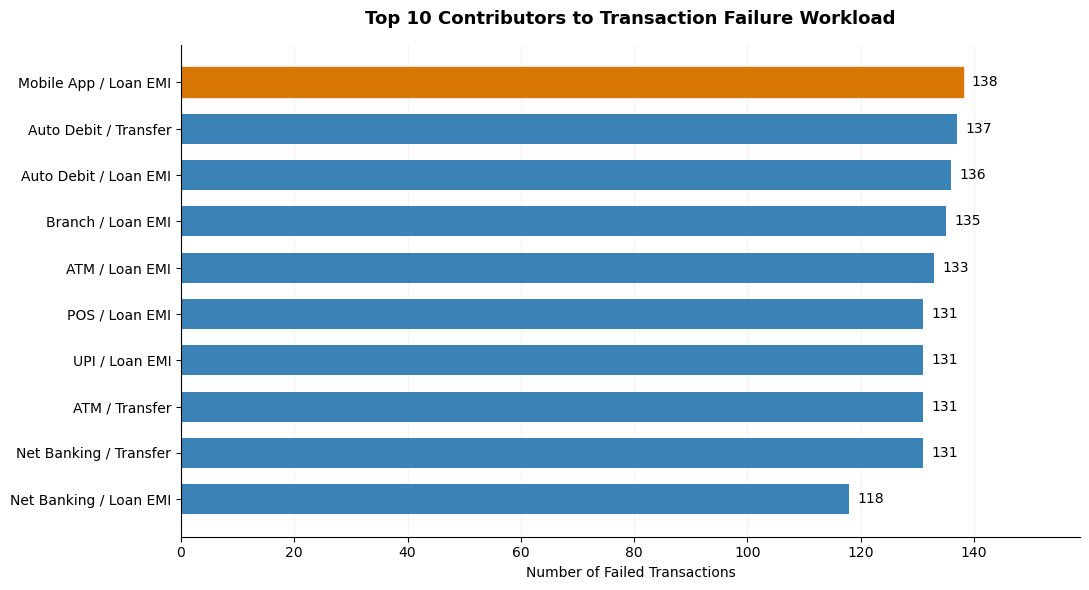

In [10]:

# Top 10 contributors to transaction failure workload

top_failures = failure_analysis.head(10).copy()

top_failures["category"] = (
    top_failures["channel"]
    + " / "
    + top_failures["transaction_type"]
)

# Sort for horizontal visualization
top_failures = top_failures.sort_values("failed_transactions")

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    top_failures["category"],
    top_failures["failed_transactions"],
    color="#3B82B6",
    height=0.65
)

# Highlight the largest failure contributor
bars[-1].set_color("#D97706")

for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 1.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=10
    )

ax.set_xlim(
    0,
    top_failures["failed_transactions"].max() * 1.15
)

ax.set_xlabel("Number of Failed Transactions")
ax.set_ylabel("")
ax.set_title(
    "Top 10 Contributors to Transaction Failure Workload",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 4.1 Operational Findings

**Key Finding:** Mobile App / Loan EMI recorded the highest failure count (138), followed by Auto Debit / Transfer (137) and Auto Debit / Loan EMI (136).

These combinations have failure rates close to the overall benchmark of **10.19%**.

**Business Interpretation:** High failure volume does not necessarily indicate an unusually high failure probability. Transaction volume must be considered before prioritizing operational interventions.

**Recommendation:** Investigate high-volume categories using failure reason codes, retry patterns, and incident records.

**Limitation:** Failure counts do not identify root causes or establish statistically significant performance differences.



### 4.2 Statistical Screening of Failure Rates

**Business Question:** Are any channel and transaction-type combinations associated with unusually elevated failure rates?

**Method:** One-sided binomial tests compare each combination's observed failure count against the overall transaction failure-rate benchmark (10.19%).

**Multiple Testing:** Benjamini–Hochberg false discovery rate (FDR) adjustment controls the expected proportion of false discoveries among rejected hypotheses.

**Significance Level:** Adjusted p-value below 0.05.

**Interpretation:** This is exploratory screening. The benchmark is estimated from the same dataset, and repeated transactions from individual customers may violate independence assumptions.


In [11]:
# Statistical screening of channel/type failure rates

# Overall failure probability
baseline_failure_rate = total_failures / len(df_channel)

# Create a separate analysis table
failure_screening = failure_analysis.copy()

# Expected failures under the overall benchmark
failure_screening["expected_failures"] = (
    failure_screening["total_transactions"]
    * baseline_failure_rate
)

# Excess failures relative to benchmark
failure_screening["excess_failures"] = (
    failure_screening["failed_transactions"]
    - failure_screening["expected_failures"]
)

# One-sided binomial tests
failure_screening["p_value"] = failure_screening.apply(
    lambda row: stats.binomtest(
        k=int(row["failed_transactions"]),
        n=int(row["total_transactions"]),
        p=baseline_failure_rate,
        alternative="greater"
    ).pvalue,
    axis=1
)

# Benjamini-Hochberg multiple-testing correction
from statsmodels.stats.multitest import multipletests

failure_screening["adjusted_p_value"] = multipletests(
    failure_screening["p_value"],
    alpha=0.05,
    method="fdr_bh"
)[1]

# Flag combinations for further investigation
failure_screening["elevated_failure_signal"] = (
    (failure_screening["adjusted_p_value"] < 0.05)
    & (failure_screening["excess_failures"] > 0)
)

# Rank by excess failures
failure_screening = failure_screening.sort_values(
    "excess_failures",
    ascending=False
)

print(f"Overall Failure Rate: {baseline_failure_rate:.2%}")

print(
    "Combinations with Elevated Failure Signals:",
    failure_screening["elevated_failure_signal"].sum()
)

display(
    failure_screening[
        [
            "channel",
            "transaction_type",
            "total_transactions",
            "failed_transactions",
            "failure_rate_pct",
            "excess_failures",
            "adjusted_p_value",
            "elevated_failure_signal"
        ]
    ].head(15).round(4)
)

Overall Failure Rate: 10.19%
Combinations with Elevated Failure Signals: 0


,channel,transaction_type,total_transactions,failed_transactions,failure_rate_pct,excess_failures,adjusted_p_value,elevated_failure_signal
0,ATM,Bill Payment,647,83,12.83,17.06,0.63,False
50,POS,Bill Payment,579,76,13.13,16.99,0.63,False
2,ATM,Deposit,684,83,12.13,13.29,0.78,False
29,Branch,Withdrawal,628,77,12.26,12.99,0.78,False
52,POS,Deposit,733,86,11.73,11.29,0.92,False
14,Auto Debit,Interest Credit,549,66,12.02,10.05,0.92,False
1,ATM,Card Payment,726,84,11.57,10.01,0.92,False
7,ATM,Refund,344,45,13.08,9.94,0.78,False
11,Auto Debit,Card Payment,747,84,11.24,7.87,0.92,False
19,Auto Debit,Withdrawal,591,68,11.51,7.77,0.92,False



### 4.3 Statistical Findings & Business Implications

**Result:** No channel and transaction-type combination showed a statistically significant elevated failure rate after Benjamini–Hochberg adjustment at the 5% FDR level.

**Business Interpretation:** The highest failure-volume categories are operationally relevant, but the available evidence does not establish unusually elevated failure probabilities for any individual combination.

**Recommendation:** Prioritize investigation using failure volume, customer impact, and available failure reason codes rather than descriptive failure rates alone.

**Limitation:** These exploratory results do not prove that all combinations have identical failure probabilities.



## 5. Time-Series Analysis & Transaction Failure Monitoring

### 5.1 Monthly Transaction Failure Trends

**Business Question:** How has transaction reliability changed over time?

**Approach:** Aggregate transaction attempts and failures by calendar month to identify changes in observed failure rates.

**KPI:** Monthly Failure Rate = Failed Transactions / Total Transaction Attempts × 100

**Business Objective:** Monitor transaction reliability and identify periods that may require further investigation.

**Note:** An above-average failure rate is not automatically a statistically significant anomaly.


Monthly Transaction Performance


,year_month,total_transactions,failed_transactions,successful_transactions,failure_rate_pct,month_date
0,2023-01,1310,134,1116,10.23,2023-01-01
1,2023-02,1125,106,972,9.42,2023-02-01
2,2023-03,1241,115,1084,9.27,2023-03-01
3,2023-04,1279,142,1085,11.10,2023-04-01
4,2023-05,1319,151,1132,11.45,2023-05-01
5,2023-06,1216,118,1056,9.70,2023-06-01
6,2023-07,1279,116,1108,9.07,2023-07-01
7,2023-08,1252,136,1064,10.86,2023-08-01
8,2023-09,1225,128,1043,10.45,2023-09-01
9,2023-10,1258,120,1075,9.54,2023-10-01



Total Months: 40


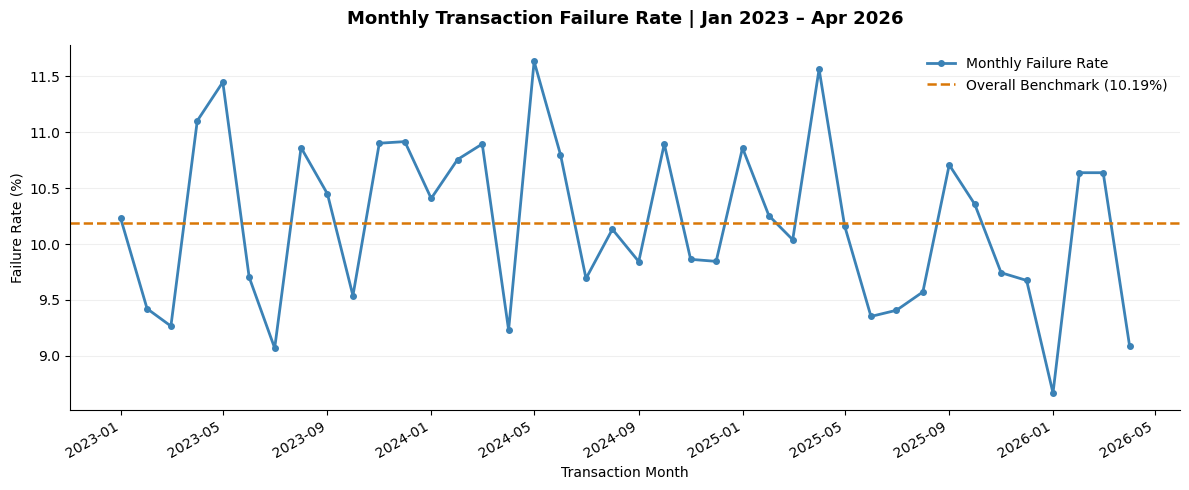

In [12]:
# Monthly transaction failure trend analysis

# Create a separate working DataFrame
df_time = df_channel.copy()

# Convert transaction dates to datetime
df_time["transaction_date"] = pd.to_datetime(
    df_time["transaction_date"],
    errors="coerce"
)

# Verify date conversion
if df_time["transaction_date"].isna().any():
    raise ValueError(
        "Invalid transaction dates found. Review date parsing."
    )

# Extract calendar month
df_time["year_month"] = (
    df_time["transaction_date"].dt.to_period("M")
)

# Create transaction outcome indicators
df_time["is_failed"] = (
    df_time["status_clean"] == "failed"
)

df_time["is_success"] = (
    df_time["status_clean"] == "success"
)

# Aggregate monthly transaction performance
monthly_performance = (
    df_time.groupby("year_month")
    .agg(
        total_transactions=("transaction_id", "count"),
        failed_transactions=("is_failed", "sum"),
        successful_transactions=("is_success", "sum")
    )
    .reset_index()
)

# Calculate monthly failure rate
monthly_performance["failure_rate_pct"] = (
    monthly_performance["failed_transactions"]
    / monthly_performance["total_transactions"]
    * 100
)

# Convert monthly periods to timestamps for plotting
monthly_performance["month_date"] = (
    monthly_performance["year_month"].dt.to_timestamp()
)

# Sort chronologically
monthly_performance = monthly_performance.sort_values(
    "month_date"
).reset_index(drop=True)

print("Monthly Transaction Performance")
display(monthly_performance.head(10).round(2))

print("\nTotal Months:", len(monthly_performance))


# Monthly transaction failure-rate trend

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_performance["month_date"],
    monthly_performance["failure_rate_pct"],
    color="#3B82B6",
    marker="o",
    markersize=4,
    linewidth=2,
    label="Monthly Failure Rate"
)

ax.axhline(
    baseline_failure_rate * 100,
    color="#D97706",
    linestyle="--",
    linewidth=1.8,
    label=f"Overall Benchmark ({baseline_failure_rate * 100:.2f}%)"
)

ax.set_title(
    "Monthly Transaction Failure Rate | Jan 2023 – Apr 2026",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Transaction Month")
ax.set_ylabel("Failure Rate (%)")

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()



### 5.2 Statistical Anomaly Screening

**Business Question:** Were any monthly failure rates unusually elevated relative to recent historical performance?

**Methodology**
- Establish a baseline using the preceding six months of transaction data.
- Test each eligible month's failure count against its historical benchmark using a one-sided binomial test.
- Apply Benjamini–Hochberg adjustment across the monthly tests.
- Flag months with adjusted p-values below 0.05.

**Coverage:** The first six months establish the initial baseline; the remaining 34 months are screened.

**Limitations:** This exploratory method treats estimated historical failure rates as fixed, assumes independent transaction outcomes, and does not explicitly account for seasonality or changing transaction composition.


In [13]:
# Statistical anomaly screening using a six-month historical baseline

from statsmodels.stats.multitest import multipletests

# Create a separate analysis table
monthly_anomalies = monthly_performance.copy()

# Calculate historical baseline and p-values
baseline_rates = []
p_values = []

for i in range(len(monthly_anomalies)):

    # First six months establish the historical baseline
    if i < 6:
        baseline_rates.append(np.nan)
        p_values.append(np.nan)
        continue

    # Previous six months only — excludes current month
    historical_data = monthly_anomalies.iloc[i-6:i]

    historical_failures = (
        historical_data["failed_transactions"].sum()
    )

    historical_attempts = (
        historical_data["total_transactions"].sum()
    )

    historical_failure_rate = (
        historical_failures / historical_attempts
    )

    # Current month observations
    current_failures = int(
        monthly_anomalies.loc[i, "failed_transactions"]
    )

    current_attempts = int(
        monthly_anomalies.loc[i, "total_transactions"]
    )

    # One-sided binomial test
    test_result = stats.binomtest(
        k=current_failures,
        n=current_attempts,
        p=historical_failure_rate,
        alternative="greater"
    )

    baseline_rates.append(historical_failure_rate * 100)
    p_values.append(test_result.pvalue)

# Store historical benchmarks and test results
monthly_anomalies["historical_failure_rate_pct"] = baseline_rates
monthly_anomalies["p_value"] = p_values

# Multiple-testing adjustment
valid_tests = monthly_anomalies["p_value"].notna()

monthly_anomalies["adjusted_p_value"] = np.nan

monthly_anomalies.loc[
    valid_tests, "adjusted_p_value"
] = multipletests(
    monthly_anomalies.loc[valid_tests, "p_value"],
    method="fdr_bh"
)[1]

# Flag statistically elevated months
monthly_anomalies["anomaly_flag"] = (
    (monthly_anomalies["adjusted_p_value"] < 0.05)
    &
    (
        monthly_anomalies["failure_rate_pct"]
        > monthly_anomalies["historical_failure_rate_pct"]
    )
)

print("Months Tested:", valid_tests.sum())

print(
    "Potential Anomalies Detected:",
    monthly_anomalies["anomaly_flag"].sum()
)

display(
    monthly_anomalies[
        [
            "year_month",
            "total_transactions",
            "failed_transactions",
            "failure_rate_pct",
            "historical_failure_rate_pct",
            "adjusted_p_value",
            "anomaly_flag"
        ]
    ].tail(15).round(4)
)

Months Tested: 34
Potential Anomalies Detected: 0


,year_month,total_transactions,failed_transactions,failure_rate_pct,historical_failure_rate_pct,adjusted_p_value,anomaly_flag
25,2025-02,1180,121,10.25,10.24,0.94,False
26,2025-03,1285,129,10.04,10.27,0.94,False
27,2025-04,1228,142,11.56,10.30,0.76,False
28,2025-05,1220,124,10.16,10.40,0.94,False
29,2025-06,1283,120,9.35,10.46,0.94,False
30,2025-07,1318,124,9.41,10.37,0.94,False
31,2025-08,1285,123,9.57,10.11,0.94,False
32,2025-09,1186,127,10.71,10.00,0.76,False
33,2025-10,1207,125,10.36,10.11,0.94,False
34,2025-11,1211,118,9.74,9.91,0.94,False



### 5.3 Findings & Business Implications

**Monitoring Results**
- Analysis period: January 2023 – April 2026
- Months analyzed: 40
- Months statistically screened: 34
- Significant elevated monthly anomalies: **0**
- Overall transaction failure rate: **10.19%**

**Business Finding:** Monthly failure rates fluctuated, but no tested month met the adjusted statistical significance threshold for an elevated failure rate.

**Recommendation:** Continue monitoring transaction reliability and investigate operational incidents using more granular timestamps, failure reason codes, and system logs.

**Limitation:** The absence of statistically significant monthly anomalies does not establish that no operational incidents occurred. Short-duration disruptions may be obscured by monthly aggregation.



## 6. Customer Behavioral Segmentation

**Business Question:** How is transaction activity distributed across customers, and which groups contribute the most transaction volume?

**Approach:** Segment customers using their recorded transaction frequency and compare each cohort's share of customers with its share of transactions.

**Segmentation Rules**
- No Recorded Activity: 0 transactions
- Low Activity: 1–7 transactions
- Medium Activity: 8–17 transactions
- High Activity: 18+ transactions

Thresholds are derived from the 25th and 75th percentiles of active-customer transaction frequency.

**Business Objective:** Identify engagement opportunities and transaction-volume concentration to support customer relationship and service planning.

**Limitation:** Activity is measured over the available observation period, without adjusting for customer tenure.


In [14]:
# Customer-level behavioral profiling

# Prepare a working copy
df_behavior = df_transactions.copy()

# Convert amount to numeric for analysis
df_behavior["amount"] = pd.to_numeric(
    df_behavior["amount"],
    errors="coerce"
)

# Use absolute transaction value for activity analysis
df_behavior["absolute_amount"] = df_behavior["amount"].abs()

# Create transaction outcome indicators
df_behavior["is_success"] = (
    df_behavior["transaction_status"] == "Success"
)

df_behavior["is_failed"] = (
    df_behavior["transaction_status"] == "Failed"
)

# Aggregate transaction behavior by customer
customer_activity = (
    df_behavior.groupby("customer_id")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_transaction_value=("absolute_amount", "sum"),
        avg_transaction_value=("absolute_amount", "mean"),
        successful_transactions=("is_success", "sum"),
        failed_transactions=("is_failed", "sum")
    )
    .reset_index()
)

# Join customer attributes while retaining customers with no transactions
customer_profile = df_customers.merge(
    customer_activity,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Fill activity metrics for customers with no recorded transactions
activity_columns = [
    "transaction_count",
    "total_transaction_value",
    "successful_transactions",
    "failed_transactions"
]

customer_profile[activity_columns] = (
    customer_profile[activity_columns].fillna(0)
)

# Classify activity within the available transaction dataset
customer_profile["activity_status"] = np.where(
    customer_profile["transaction_count"] > 0,
    "Active",
    "No Recorded Transactions"
)

# Display summary
print("Total Customers:", len(customer_profile))

print(
    "Customers With Transactions:",
    (customer_profile["activity_status"] == "Active").sum()
)

print(
    "Customers Without Transactions:",
    (
        customer_profile["activity_status"]
        == "No Recorded Transactions"
    ).sum()
)

print("\nCustomer Activity Profile:")
display(
    customer_profile[
        [
            "customer_id",
            "customer_segment",
            "transaction_count",
            "total_transaction_value",
            "avg_transaction_value",
            "successful_transactions",
            "failed_transactions",
            "activity_status"
        ]
    ].head(10).round(2)
)

Total Customers: 5000
Customers With Transactions: 3983
Customers Without Transactions: 1017

Customer Activity Profile:


,customer_id,customer_segment,transaction_count,total_transaction_value,avg_transaction_value,successful_transactions,failed_transactions,activity_status
0,C00001,SME,15.00,"122,056.26","8,137.08",15.00,0.00,Active
1,C00002,Premium,0.00,0.00,NaN,0.00,0.00,No Recorded Transactions
2,C00003,Retail,18.00,"130,326.69","7,240.37",17.00,1.00,Active
3,C00004,Retail,0.00,0.00,NaN,0.00,0.00,No Recorded Transactions
4,C00005,SME,13.00,"139,014.86","10,693.45",10.00,2.00,Active
5,C00006,Corporate,12.00,"81,537.40","6,794.78",10.00,1.00,Active
6,C00007,Corporate,0.00,0.00,NaN,0.00,0.00,No Recorded Transactions
7,C00008,Wealth,6.00,"51,829.35","8,638.22",6.00,0.00,Active
8,C00009,Wealth,0.00,0.00,NaN,0.00,0.00,No Recorded Transactions
9,C00010,Retail,16.00,"213,951.68","13,371.98",16.00,0.00,Active



### 6.2 Customer Activity Segmentation

Customers are classified into four behavioral cohorts using their recorded transaction frequency.

**Segmentation Results**
- **No Recorded Transactions:** 1,017 customers (20.34%); no transaction contribution.
- **Low Activity:** 1,224 customers (24.48%); 12.46% of transactions.
- **Medium Activity:** 1,863 customers (37.26%); 44.63% of transactions.
- **High Activity:** 896 customers (17.92%); 42.91% of transactions.

**Key Finding:** High-activity customers represent less than one-fifth of the customer base but account for approximately 43% of transaction volume.

**Business Implications**
- Evaluate engagement opportunities for customers with limited recorded activity.
- Monitor service reliability for high-frequency customers.
- Use behavioral cohorts alongside existing customer classifications for targeted analysis.

**Limitation:** Transaction frequency alone does not measure customer value, profitability, or churn risk.


In [15]:
# Customer behavioral segmentation using transaction frequency

# Create a working copy
customer_segments = customer_profile.copy()

# Select customers with recorded transactions
active_counts = customer_segments.loc[
    customer_segments["transaction_count"] > 0,
    "transaction_count"
]

# Calculate activity thresholds
q25 = active_counts.quantile(0.25)
q75 = active_counts.quantile(0.75)

print(f"25th Percentile: {q25:.0f} transactions")
print(f"75th Percentile: {q75:.0f} transactions")

# Assign behavioral cohorts
customer_segments["behavior_segment"] = np.select(
    [
        customer_segments["transaction_count"] == 0,
        customer_segments["transaction_count"] <= q25,
        customer_segments["transaction_count"] <= q75
    ],
    [
        "No Recorded Transactions",
        "Low Activity",
        "Medium Activity"
    ],
    default="High Activity"
)

# Summarize customer behavior by cohort
behavior_summary = (
    customer_segments.groupby("behavior_segment")
    .agg(
        customers=("customer_id", "count"),
        total_transactions=("transaction_count", "sum"),
        avg_transactions_per_customer=("transaction_count", "mean"),
        total_transaction_value=("total_transaction_value", "sum")
    )
    .reset_index()
)

# Calculate percentage of customer base
behavior_summary["customer_share_pct"] = (
    behavior_summary["customers"]
    / len(customer_segments)
    * 100
)

# Calculate share of transaction activity
behavior_summary["transaction_share_pct"] = (
    behavior_summary["total_transactions"]
    / customer_segments["transaction_count"].sum()
    * 100
)

# Display cohorts in business order
segment_order = [
    "No Recorded Transactions",
    "Low Activity",
    "Medium Activity",
    "High Activity"
]

behavior_summary["behavior_segment"] = pd.Categorical(
    behavior_summary["behavior_segment"],
    categories=segment_order,
    ordered=True
)

behavior_summary = behavior_summary.sort_values(
    "behavior_segment"
)

display(behavior_summary.round(2))

25th Percentile: 7 transactions
75th Percentile: 17 transactions


,behavior_segment,customers,total_transactions,avg_transactions_per_customer,total_transaction_value,customer_share_pct,transaction_share_pct
3,No Recorded Transactions,1017,0.00,0.00,0.00,20.34,0.00
1,Low Activity,1224,"6,231.00",5.09,"58,832,109.29",24.48,12.46
2,Medium Activity,1863,"22,315.00",11.98,"202,216,157.82",37.26,44.63
0,High Activity,896,"21,454.00",23.94,"194,485,982.51",17.92,42.91


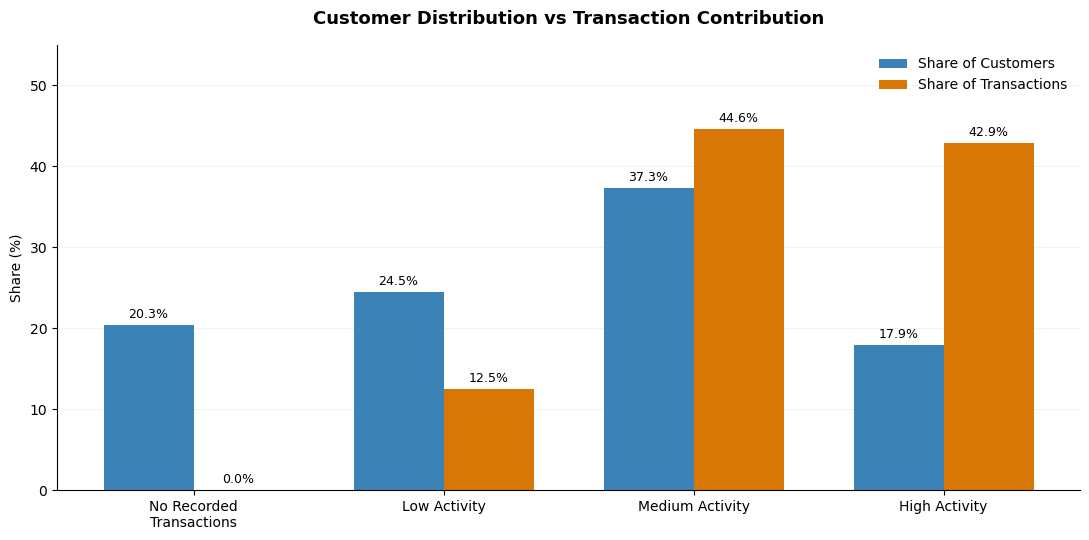

In [16]:

# Customer share vs transaction share by behavioral cohort

segment_plot = behavior_summary.copy()

segment_order = [
    "No Recorded Transactions",
    "Low Activity",
    "Medium Activity",
    "High Activity"
]

segment_plot = (
    segment_plot
    .set_index("behavior_segment")
    .reindex(segment_order)
)

x = np.arange(len(segment_plot))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5.5))

bars_customers = ax.bar(
    x - width / 2,
    segment_plot["customer_share_pct"],
    width,
    label="Share of Customers",
    color="#3B82B6"
)

bars_transactions = ax.bar(
    x + width / 2,
    segment_plot["transaction_share_pct"],
    width,
    label="Share of Transactions",
    color="#D97706"
)

for bars in [bars_customers, bars_transactions]:
    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels([
    "No Recorded\nTransactions",
    "Low Activity",
    "Medium Activity",
    "High Activity"
])

ax.set_ylabel("Share (%)")
ax.set_title(
    "Customer Distribution vs Transaction Contribution",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_ylim(0, 55)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()



### 6.3 Customer Behavioral Segmentation — Key Findings

**Segmentation Method:** Transaction frequency quartiles among customers with recorded activity (Q1 = 7, Q3 = 17 transactions).

**Key Findings:**
- High Activity: 896 customers (17.92%) generated 42.91% of all transactions.
- Medium Activity: 1,863 customers (37.26%) generated 44.63% of transactions.
- Low Activity: 1,224 customers (24.48%) generated 12.46% of transactions.
- No Recorded Transactions: 1,017 customers (20.34%).

**Business Implications:**
- High-activity customers represent an important group for monitoring transaction reliability and service experience.
- Low-activity customers may be candidates for engagement initiatives.
- Customers without recorded transactions warrant further investigation before being classified as inactive or at risk of churn.

**Recommendations:**
1. Monitor service reliability and transaction failures among high-activity customers.
2. Evaluate targeted engagement initiatives for low-activity customers.
3. Investigate account tenure and other product usage before designing activation campaigns.
4. Measure campaign effectiveness using controlled experiments rather than assuming increased engagement.

**Limitations:** Cohorts reflect cumulative transaction counts over the available dataset. They are not profitability, customer lifetime value, or churn-risk classifications.



### 6.4 Behavioral Activity Across Existing Customer Segments

**Business Question:** Do traditional customer segments reflect differences in transaction activity?

**Approach:** Compare the percentage distribution of behavioral cohorts within Retail, Premium, SME, Corporate, and Wealth customers.

**Business Objective:** Assess whether transaction-frequency segmentation adds useful information to existing customer classifications.

**Limitation:** Results are descriptive and do not account for differences in customer tenure.


Customer Counts by Segment and Activity Level:


behavior_segment,No Recorded Transactions,Low Activity,Medium Activity,High Activity
customer_segment,,,,
Corporate,90,88,134,62
Premium,184,211,329,171
Retail,526,686,1008,483
SME,164,169,301,146
Wealth,53,70,91,34



Activity Distribution Within Each Customer Segment (%):


behavior_segment,No Recorded Transactions,Low Activity,Medium Activity,High Activity
customer_segment,,,,
Corporate,24.06,23.53,35.83,16.58
Premium,20.56,23.58,36.76,19.11
Retail,19.46,25.38,37.29,17.87
SME,21.03,21.67,38.59,18.72
Wealth,21.37,28.23,36.69,13.71


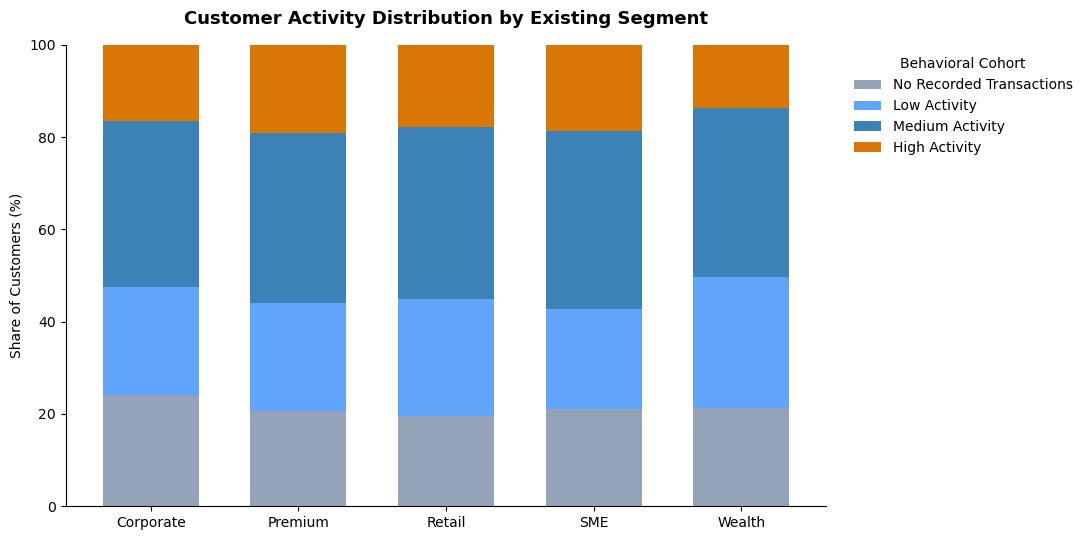

In [17]:
# Behavioral activity distribution across customer segments

# Count customers by existing segment and behavioral cohort
segment_behavior = pd.crosstab(
    customer_segments["customer_segment"],
    customer_segments["behavior_segment"]
)

# Arrange columns in logical order
segment_behavior = segment_behavior.reindex(
    columns=segment_order,
    fill_value=0
)

# Calculate percentages within each customer segment
segment_behavior_pct = (
    segment_behavior.div(
        segment_behavior.sum(axis=1),
        axis=0
    ) * 100
)

print("Customer Counts by Segment and Activity Level:")
display(segment_behavior)

print("\nActivity Distribution Within Each Customer Segment (%):")
display(segment_behavior_pct.round(2))


# Visualize behavioral activity across existing customer segments

colors = [
    "#94A3B8",  # No recorded transactions
    "#60A5FA",  # Low activity
    "#3B82B6",  # Medium activity
    "#D97706"   # High activity
]

ax = segment_behavior_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5.5),
    color=colors,
    width=0.65
)

ax.set_title(
    "Customer Activity Distribution by Existing Segment",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("")
ax.set_ylabel("Share of Customers (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Behavioral Cohort",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()



### 6.5 Customer Segmentation — Business Findings

**Key Findings**
- **Premium:** Highest high-activity customer share (19.11%).
- **Wealth:** Lowest high-activity customer share (13.71%).
- **Corporate:** Highest share of customers with no recorded transactions (24.06%).
- Every existing customer segment contains customers across multiple behavioral activity levels.

**Business Interpretation:** Traditional customer classifications do not fully describe transaction engagement. Behavioral cohorts provide an additional dimension for customer analysis.

**Recommendation:** Combine existing customer segments with transaction-frequency cohorts when evaluating engagement initiatives and service requirements.

**Limitation:** Differences are descriptive, not causal, and may reflect customer tenure or other unmeasured factors.



## 7. Risk Threshold Sensitivity Analysis

**Business Question:** How do different risk-score thresholds affect investigation workload and coverage of existing fraud flags?

**Approach:** Evaluate risk-score thresholds from 50 to 90, comparing the number of transactions selected for review with the proportion of existing fraud flags included.

**Key Metrics**
- **Review Workload:** Transactions with risk scores at or above the threshold.
- **Review Rate:** Selected transactions / Total transactions × 100.
- **Existing Flag Coverage:** Flagged transactions selected / All existing flagged transactions × 100.
- **Flag Concentration:** Existing flagged transactions / Selected transactions × 100.

**Business Objective:** Support investigation-capacity planning by quantifying workload-versus-coverage trade-offs.

**Critical Limitation:** Existing fraud flags are not independently verified fraud outcomes. Risk scores and flags may be dependent, so these results must not be interpreted as validated fraud-detection accuracy.


Total Transactions: 50000
Total Existing Fraud Flags: 630


,risk_threshold,transactions_for_review,review_workload_pct,flags_captured,flag_coverage_pct,flag_concentration_pct
0,50,15371,30.74,630,100.00,4.10
1,55,11892,23.78,630,100.00,5.30
2,60,8334,16.67,630,100.00,7.56
3,65,4884,9.77,630,100.00,12.90
4,70,1212,2.42,535,84.92,44.14
5,75,460,0.92,460,73.02,100.00
6,80,377,0.75,377,59.84,100.00
7,85,290,0.58,290,46.03,100.00
8,90,219,0.44,219,34.76,100.00


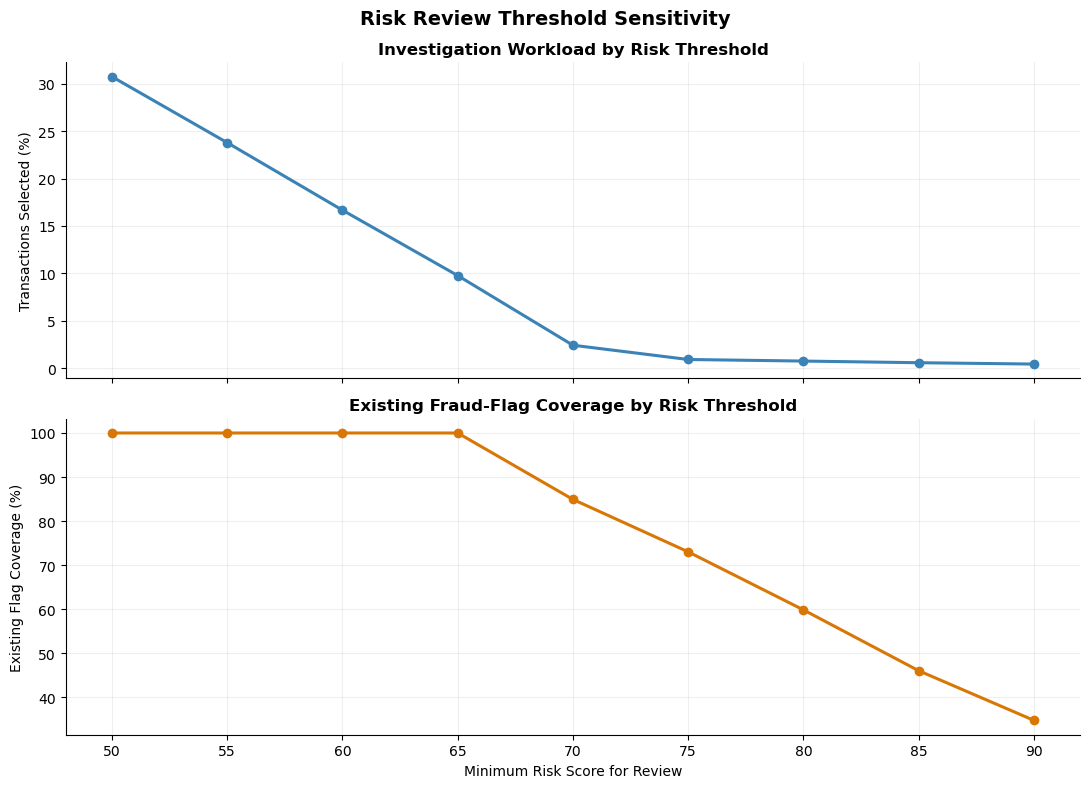

In [18]:
# Risk-score threshold sensitivity analysis

# Prepare risk analysis dataset
df_risk = df_transactions.copy()

df_risk["risk_score"] = pd.to_numeric(
    df_risk["risk_score"],
    errors="coerce"
)

df_risk["fraud_flag"] = (
    df_risk["is_fraud"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("yes")
)

# Validate required risk fields
if df_risk["risk_score"].isna().any():
    raise ValueError("Missing or invalid risk scores found.")

total_transactions = len(df_risk)
total_flags = int(df_risk["fraud_flag"].sum())

# Candidate review thresholds
thresholds = [50, 55, 60, 65, 70, 75, 80, 85, 90]

results = []

for threshold in thresholds:

    selected = df_risk["risk_score"] >= threshold

    review_count = int(selected.sum())

    flags_captured = int(
        (selected & df_risk["fraud_flag"]).sum()
    )

    review_workload_pct = (
        review_count / total_transactions * 100
    )

    flag_coverage_pct = (
        flags_captured / total_flags * 100
        if total_flags > 0 else np.nan
    )

    flag_concentration_pct = (
        flags_captured / review_count * 100
        if review_count > 0 else np.nan
    )

    results.append({
        "risk_threshold": threshold,
        "transactions_for_review": review_count,
        "review_workload_pct": review_workload_pct,
        "flags_captured": flags_captured,
        "flag_coverage_pct": flag_coverage_pct,
        "flag_concentration_pct": flag_concentration_pct
    })

risk_threshold_summary = pd.DataFrame(results)

print("Total Transactions:", total_transactions)
print("Total Existing Fraud Flags:", total_flags)

display(risk_threshold_summary.round(2))


# Risk threshold sensitivity visualization

plot_data = risk_threshold_summary.sort_values("risk_threshold")

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

# Investigation workload
axes[0].plot(
    plot_data["risk_threshold"],
    plot_data["review_workload_pct"],
    marker="o",
    linewidth=2.2,
    color="#3B82B6"
)

axes[0].set_ylabel("Transactions Selected (%)")
axes[0].set_title(
    "Investigation Workload by Risk Threshold",
    fontweight="bold"
)
axes[0].grid(alpha=0.2)

# Existing fraud-flag coverage
axes[1].plot(
    plot_data["risk_threshold"],
    plot_data["flag_coverage_pct"],
    marker="o",
    linewidth=2.2,
    color="#D97706"
)

axes[1].set_ylabel("Existing Flag Coverage (%)")
axes[1].set_xlabel("Minimum Risk Score for Review")
axes[1].set_title(
    "Existing Fraud-Flag Coverage by Risk Threshold",
    fontweight="bold"
)
axes[1].grid(alpha=0.2)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Risk Review Threshold Sensitivity",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 7.1 Risk Threshold Findings & Business Recommendations

**Key Findings**

- **Threshold ≥65:** 4,884 transactions selected (9.77% workload), covering 100% of existing fraud flags.
- **Threshold ≥70:** 1,212 transactions selected (2.42% workload), covering 84.92% of existing fraud flags.
- **Threshold ≥75:** 460 transactions selected (0.92% workload), covering 73.02% of existing fraud flags.

**Operational Trade-off**

Increasing the threshold from 65 to 70 reduces the review queue by **3,672 transactions (75.2%)**, but excludes **95 transactions with existing fraud flags**.

**Business Recommendations**

1. **Capacity Planning:** Use threshold scenarios to estimate investigation workload under different staffing constraints.
2. **Risk Governance:** Evaluate the consequences of excluding flagged transactions before changing review policies.
3. **Independent Validation:** Assess thresholds using independently confirmed fraud outcomes, investigation costs, and false-positive impacts.

**Critical Limitation**

Existing fraud flags may depend on the same risk scores used for threshold selection. Therefore, these results describe existing flag coverage—not validated fraud detection performance.

**Conclusion**

Threshold selection involves a measurable workload-versus-coverage trade-off. No threshold can be recommended as optimal without independent outcome validation and business cost information.



## 8. Executive Summary & Business Recommendations

### Project Overview

Analyzed **50,000 financial transactions** and **5,000 customer records** using SQL Server, Python, statistical testing, and Power BI to investigate transaction reliability, customer engagement, and risk-review workload.

### Key Business Findings

| Business Area | Key Finding | Business Implication |
|---|---|---|
| Transaction Reliability | **10.19%** overall failure rate | Monitor operational failures and investigate recurring issues |
| Statistical Testing | Channel association p-value = **0.0982** | No statistically significant overall channel association detected |
| Monthly Monitoring | **0 significant elevated months** across 34 screened | Continue monitoring; shorter incidents may remain undetected |
| Customer Engagement | **17.92%** of customers generated **42.91%** of transactions | Consider behavioral cohorts for engagement and service planning |
| Risk Operations | Threshold ≥70 selects **2.42%** of transactions while covering **84.92%** of existing flags | Evaluate review capacity against flag coverage |

### Recommended Business Actions

**1. Improve Operational Monitoring**

Track failure rates alongside transaction volumes and investigate high-impact categories using failure reason codes and incident records.

**2. Strengthen Customer Engagement Analysis**

Use transaction-frequency cohorts alongside existing customer segments to identify engagement opportunities and support service-capacity planning.

**3. Support Risk Investigation Planning**

Evaluate alternative review thresholds based on workload, existing flag coverage, investigation costs, and independently confirmed outcomes.

**4. Maintain Data Governance**

Preserve SQL validation controls and consistent KPI definitions across Python analysis and Power BI reporting.

### Analytical Limitations

- Historical observational data does not establish causation.
- Statistical screening is exploratory and may miss short-duration incidents.
- Customer activity does not establish profitability or churn risk.
- Existing fraud flags are not independently verified fraud outcomes.
- Recommendations represent potential actions; no realized business impact is claimed.

### Final Conclusion

**The analysis supports evidence-based operational prioritization rather than unverified performance claims.**

By combining validated SQL data, Python statistical analysis, customer segmentation, and Power BI reporting, the project demonstrates an end-to-end financial analytics workflow.
